<a href="https://colab.research.google.com/github/GavrilLaura/PMP-2026/blob/main/PARTIAL/pmp_partial.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#**PARTIAL**

In [14]:
!pip install -q hmmlearn

import numpy as np
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
from scipy import stats
from hmmlearn import hmm

### **Subiectul 1**

In [15]:
camere = ["1", "2", "3", "4"]
culori = ["red", "green", "blue"]

secventa = ["red", "green", "blue", "blue", "red"]

pi = np.array([0.25, 0.25, 0.25, 0.25])

B = np.array([
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6],
    [0.5, 0.2, 0.3]
])

A1 = np.array([
    [0.2, 0.4, 0.0, 0.4],
    [0.4, 0.2, 0.4, 0.0],
    [0.0, 0.4, 0.2, 0.4],
    [0.4, 0.0, 0.4, 0.2]
])

A2 = np.array([
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0],
    [0.0, 0.5, 0.0, 0.5],
    [0.5, 0.0, 0.5, 0.0]
])

obs = []
for c in secventa:
    obs.append(culori.index(c))
obs_coloana = np.array(obs).reshape(-1, 1)

def viterbi_hmmlearn(A):
    model = hmm.CategoricalHMM(n_components=4, init_params="")
    model.startprob_ = pi
    model.transmat_ = A
    model.emissionprob_ = B
    log_p, drum = model.decode(obs_coloana, algorithm="viterbi")
    drum_nume = []
    for s in drum:
        drum_nume.append(camere[s])
    return drum_nume, np.exp(log_p)

In [16]:
# a)

drum_a, p_a = viterbi_hmmlearn(A1)
print("(a) Secventa de camere:", drum_a)
print("(a) P(secventa, observatii) =", p_a)


(a) Secventa de camere: ['1', '2', '3', '4', '1']
(a) P(secventa, observatii) = 0.000338688


In [17]:
# b)

drum_b, p_b = viterbi_hmmlearn(A2)
print("(b) Secventa de camere:", drum_b)
print("(b) P(secventa, observatii) =", p_b)

(b) Secventa de camere: ['1', '2', '3', '4', '1']
(b) P(secventa, observatii) = 0.0008268749999999998


###**Subiectul 2**

In [18]:
# a) rezolvare pe foaie

In [19]:
# b) rezolvare pe foaie

### **Subiectul 3**

In [20]:
alpha_prior = 2
beta_prior = 8

In [21]:
# a)

alpha_a = alpha_prior + 5
beta_a = beta_prior + 20 - 5
post_a = stats.beta(alpha_a, beta_a)
print("(a) Posterior: Beta(", alpha_a, ",", beta_a, "), media =", round(post_a.mean(), 4))

(a) Posterior: Beta( 7 , 23 ), media = 0.2333


In [22]:
# b)

alpha_b = alpha_a + 3
beta_b = beta_a + 15 - 3
post_b = stats.beta(alpha_b, beta_b)
print("(b) Posterior dupa ambele loturi: Beta(", alpha_b, ",", beta_b, "), media =", round(post_b.mean(), 4))

(b) Posterior dupa ambele loturi: Beta( 10 , 35 ), media = 0.2222


In [23]:
# c)

alpha_c = alpha_prior + 3
beta_c = beta_prior + 15 - 3
post_c = stats.beta(alpha_c, beta_c)
print("(c) Posterior doar lotul 2: Beta(", alpha_c, ",", beta_c, "), media =", round(post_c.mean(), 4))

(c) Posterior doar lotul 2: Beta( 5 , 20 ), media = 0.2


In [24]:
print("Deviatia standard: (b) =", round(post_b.std(), 4), "  (c) =", round(post_c.std(), 4))

Deviatia standard: (b) = 0.0613   (c) = 0.0784


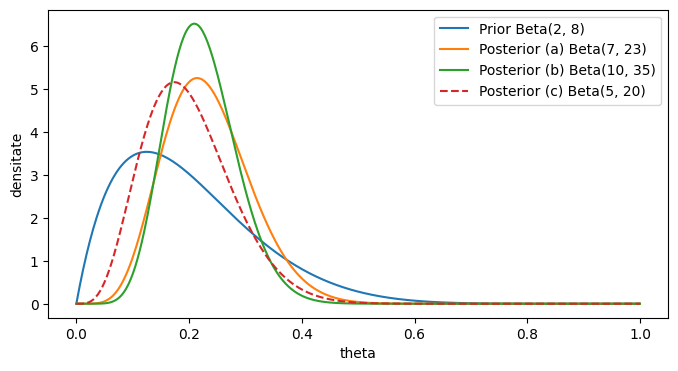

In [25]:
prior = stats.beta(alpha_prior, beta_prior)
x = np.linspace(0, 1, 500)
plt.figure(figsize=(8, 4))
plt.plot(x, prior.pdf(x), label="Prior Beta(2, 8)")
plt.plot(x, post_a.pdf(x), label="Posterior (a) Beta(7, 23)")
plt.plot(x, post_b.pdf(x), label="Posterior (b) Beta(10, 35)")
plt.plot(x, post_c.pdf(x), label="Posterior (c) Beta(5, 20)", linestyle="--")
plt.xlabel("theta")
plt.ylabel("densitate")
plt.legend()
plt.savefig("beta_posterior.png")
plt.show()

**Comparație b) vs c)**

La b), posteriorul Beta(10, 35) foloseste ambele loturi (35 de produse, 8 defecte), iar la c) posteriorul Beta(5, 20) foloseste doar lotul 2 (15 produse, 3 defecte). De aceea b) este mai sigur (deviatie standard = aprox. 0.061 fata de aprox 0.078).

Media la b) este putin mai mare (aprox 0.222 fata de 0.2), deoarece primul lot avea o rata de defectare mai mare (5/20 = 25%).

Diferenta provine din informatia suplimentara adusa de primul lot.